# 02 — Preprocessing Verification: Raw vs. Cleaned Waveforms & Spectra

Direct before/after verification of `combined/preprocessing.py` on representative records from each source dataset — proving baseline wander removal, `400 Hz → 500 Hz` resampling, `50/60 Hz` mains notch suppression, and Savitzky-Golay smoothing.

/tmp/ipykernel_633190/727201898.py:34: DtypeWarning: Columns (1: source_record_id, 4: sex, 7: raw_labels) have mixed types. Specify dtype option on import or set low_memory=False.
  meta = pd.read_csv(DATA_DIR / "metadata.csv.gz")


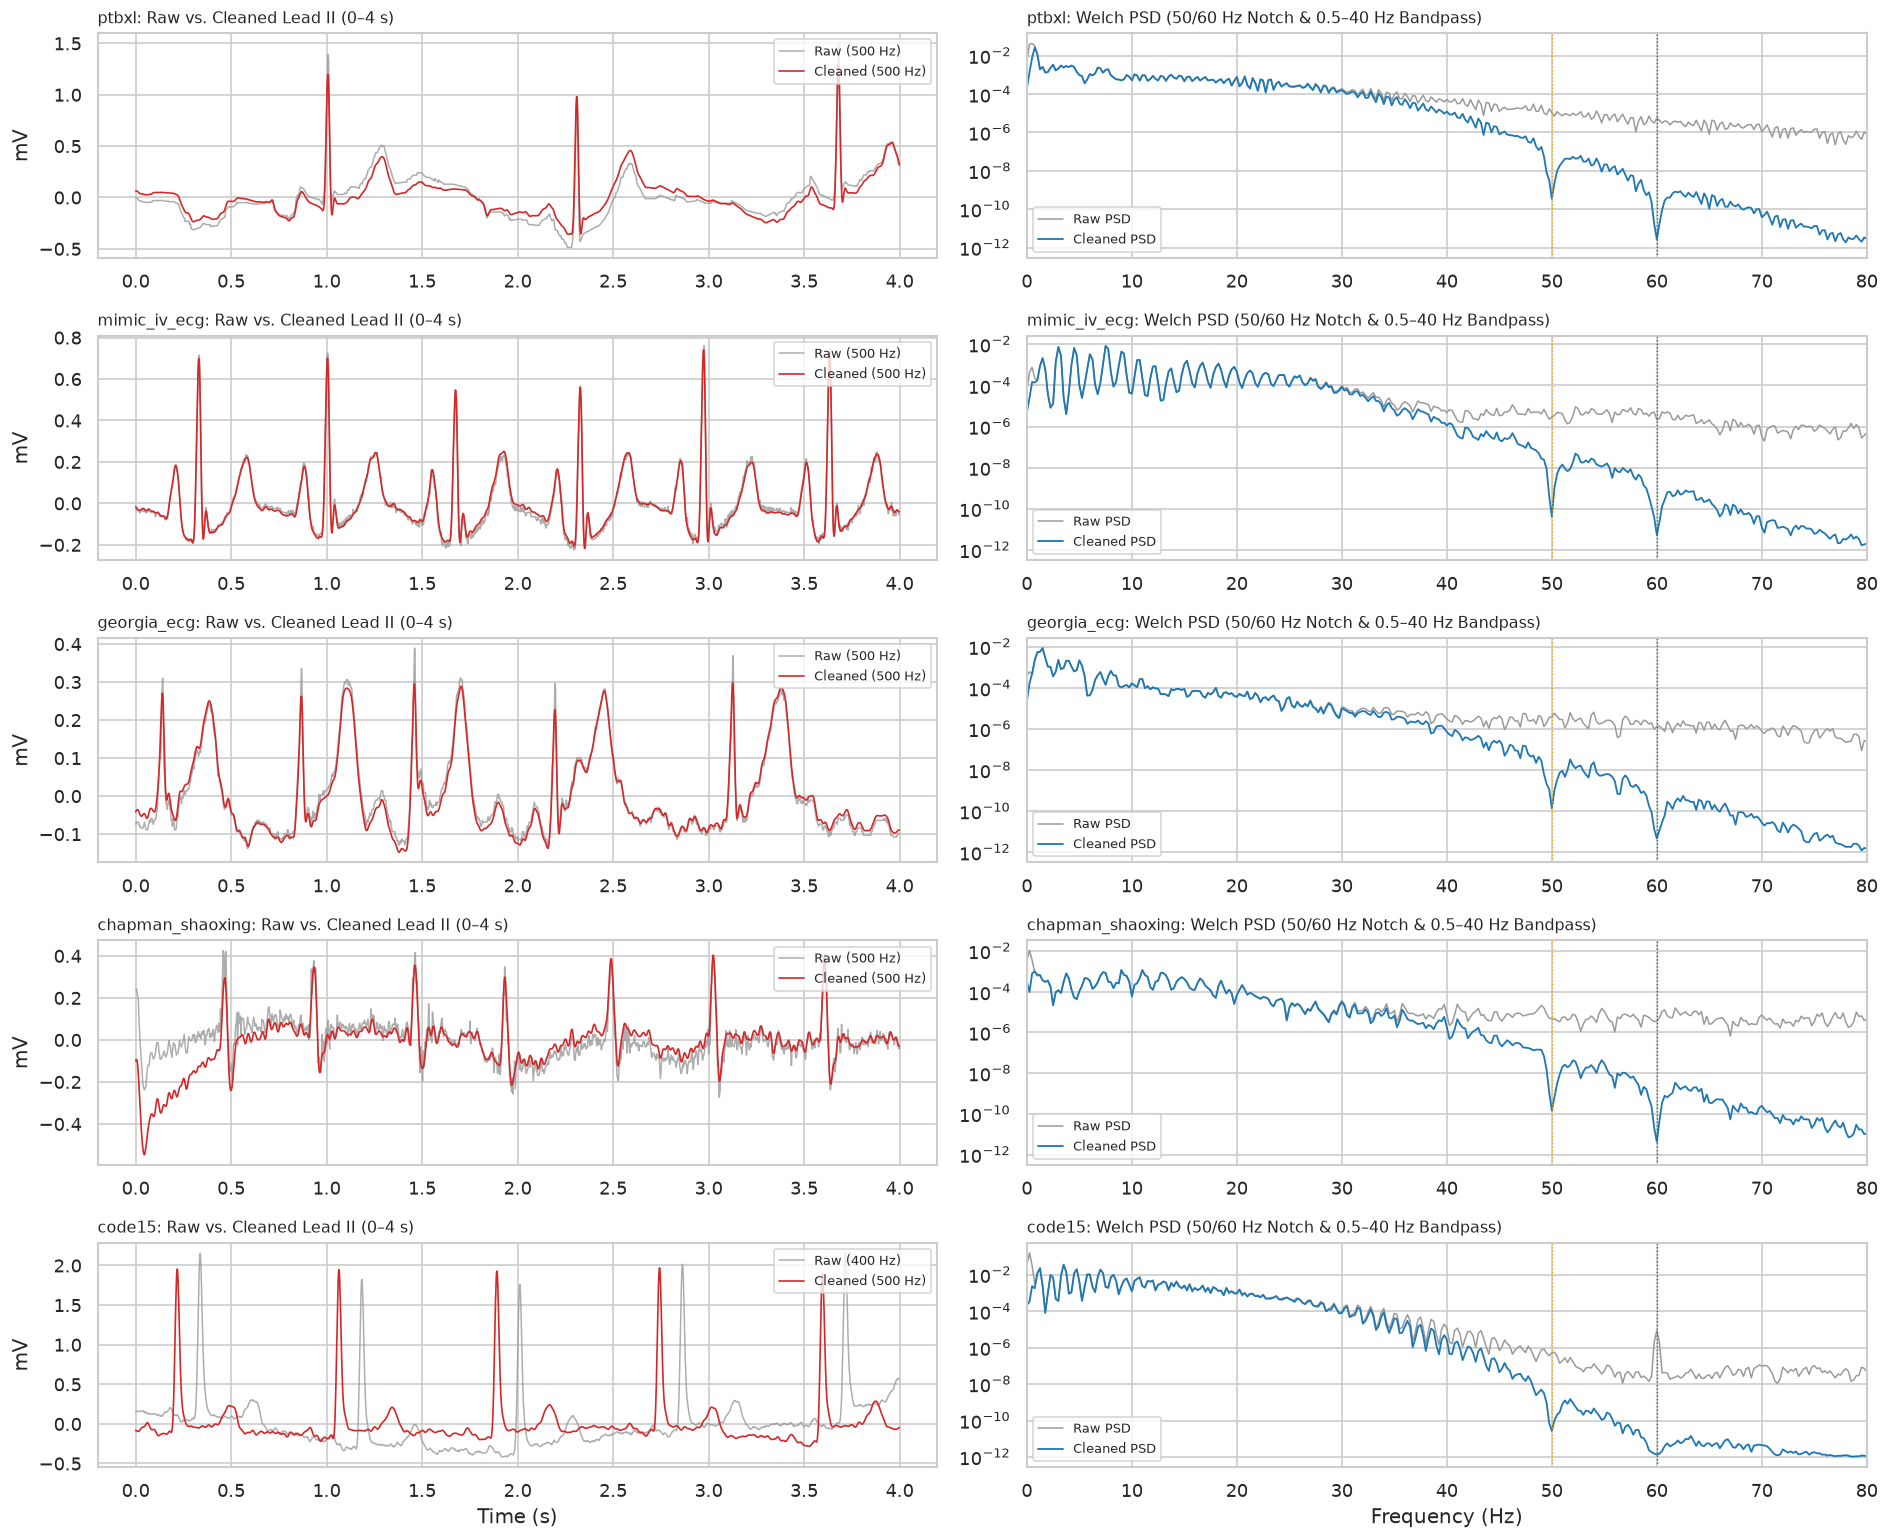

In [1]:
import json, sys, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight"})

_cwd = Path.cwd().resolve()
for _cand in [_cwd, _cwd.parent, _cwd.parent.parent]:
    if (_cand / "combined" / "quality" / "error_labels.csv.gz").exists():
        REPO_ROOT = _cand
        break
else:
    raise FileNotFoundError(f"Could not locate combined/quality/error_labels.csv.gz from {_cwd}")

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from combined import CombinedECGDataset
COMBINED_DIR = REPO_ROOT / "combined"
DATA_DIR = COMBINED_DIR / "data"
QUALITY_DIR = COMBINED_DIR / "quality"
LEADS = CombinedECGDataset.LEADS

import h5py, wfdb
from scipy.signal import welch
from combined.preprocessing import PreprocessConfig, preprocess_ecg

meta = pd.read_csv(DATA_DIR / "metadata.csv.gz")
cfg_json = json.loads((DATA_DIR / "build_config.json").read_text())
pp_cfg = PreprocessConfig(
    target_fs=cfg_json["preprocess_config"]["target_fs"],
    target_duration_s=cfg_json["preprocess_config"]["target_duration_s"],
    bandpass_low_hz=cfg_json["preprocess_config"]["bandpass_low_hz"],
    bandpass_high_hz=cfg_json["preprocess_config"]["bandpass_high_hz"],
    smooth=cfg_json["preprocess_config"]["smooth"],
    normalize=cfg_json["preprocess_config"]["normalize"],
)

# Load 1 raw + preprocessed example per source
examples = {}
ptb_db = pd.read_csv(REPO_ROOT / "ptbxl" / "data" / "ptbxl_database.csv", usecols=["ecg_id", "filename_hr"]).set_index("ecg_id")
mimic_rec = pd.read_csv(REPO_ROOT / "mimic_iv_ecg" / "data" / "record_list.csv", usecols=["study_id", "path"]).set_index("study_id")
geo_err = pd.read_csv(REPO_ROOT / "georgia_ecg" / "quality" / "error_labels.csv", usecols=["record_id", "record_path"]).set_index("record_id")
chap_err = pd.read_csv(REPO_ROOT / "chapman_shaoxing" / "quality" / "error_labels.csv", usecols=["record_id", "record_path"]).set_index("record_id")

for src in ["ptbxl", "mimic_iv_ecg", "georgia_ecg", "chapman_shaoxing", "code15"]:
    row = meta[meta["source_dataset"] == src].iloc[0]
    rid = row["source_record_id"]
    if src == "ptbxl":
        raw, _ = wfdb.rdsamp(str(REPO_ROOT / "ptbxl" / "data" / ptb_db.loc[int(rid), "filename_hr"]))
        raw, orig_fs, trim = raw.T, 500, False
    elif src == "mimic_iv_ecg":
        raw, _ = wfdb.rdsamp(str(REPO_ROOT / "mimic_iv_ecg" / "data" / mimic_rec.loc[int(rid), "path"]))
        raw, orig_fs, trim = raw.T, 500, False
    elif src == "georgia_ecg":
        raw, _ = wfdb.rdsamp(str(REPO_ROOT / "georgia_ecg" / "data" / geo_err.loc[rid, "record_path"]))
        raw, orig_fs, trim = raw.T, 500, False
    elif src == "chapman_shaoxing":
        raw, _ = wfdb.rdsamp(str(REPO_ROOT / "chapman_shaoxing" / "data" / chap_err.loc[rid, "record_path"]))
        raw, orig_fs, trim = raw.T, 500, False
    else:
        with h5py.File(REPO_ROOT / "code15" / "data" / "exams_part0.hdf5", "r") as f:
            ids = np.array(f["exam_id"])
            pos = int(np.where(ids == int(rid))[0][0])
            raw = np.array(f["tracings"][pos]).T
        orig_fs, trim = 400, True
    proc = preprocess_ecg(raw, orig_fs=orig_fs, cfg=pp_cfg, trim_zero_pad=trim)
    examples[src] = (raw, orig_fs, proc)

fig, axes = plt.subplots(5, 2, figsize=(16, 13))
for i, src in enumerate(["ptbxl", "mimic_iv_ecg", "georgia_ecg", "chapman_shaoxing", "code15"]):
    raw, orig_fs, proc = examples[src]
    # Left: 0-4 s Lead II raw vs preprocessed
    t_raw = np.arange(min(raw.shape[1], int(4 * orig_fs))) / orig_fs
    t_proc = np.arange(2000) / 500.0
    axes[i, 0].plot(t_raw, raw[1, :len(t_raw)] - np.mean(raw[1, :len(t_raw)]), color="#999999", lw=0.9, alpha=0.8, label=f"Raw ({orig_fs} Hz)")
    axes[i, 0].plot(t_proc, proc[1, :2000], color="#d62728", lw=1.0, label="Cleaned (500 Hz)")
    axes[i, 0].set_title(f"{src}: Raw vs. Cleaned Lead II (0–4 s)", loc="left", fontsize=9.5)
    axes[i, 0].set_ylabel("mV")
    axes[i, 0].legend(fontsize=7.5, loc="upper right")

    # Right: Welch PSD raw vs preprocessed
    f_r, p_r = welch(raw[1] - np.mean(raw[1]), fs=orig_fs, nperseg=min(raw.shape[1], orig_fs * 4))
    f_p, p_p = welch(proc[1], fs=500, nperseg=2000)
    axes[i, 1].semilogy(f_r, p_r + 1e-12, color="#999999", lw=0.9, label="Raw PSD")
    axes[i, 1].semilogy(f_p, p_p + 1e-12, color="#1f78b4", lw=1.1, label="Cleaned PSD")
    axes[i, 1].axvline(50, color="orange", ls=":", lw=0.8)
    axes[i, 1].axvline(60, color="green", ls=":", lw=0.8)
    axes[i, 1].set_xlim(0, 80)
    axes[i, 1].set_title(f"{src}: Welch PSD (50/60 Hz Notch & 0.5–40 Hz Bandpass)", loc="left", fontsize=9.5)
    axes[i, 1].legend(fontsize=7.5, loc="lower left")

axes[-1, 0].set_xlabel("Time (s)")
axes[-1, 1].set_xlabel("Frequency (Hz)")
plt.tight_layout()
plt.show()
